# Лабораторная работа № 1. Нейронные сети
## Обучение полносвязных нейронных сетей: классификаторы и регрессор
**Вариант 5 (нечётная цифра):**
| Задача | Набор данных | Целевой признак |
|---|---|---|
| Бинарная классификация | Diabetes Health Indicators (Kaggle) | `Diabetes_012` → 0 — нет диабета, 1 — преддиабет/диабет (значения 1 и 2 объединены) |
| Многоклассовая классификация | Body Performance (Kaggle) | `class` (A, B, C, D) |
| Регрессия | Wine Quality, `winequality-white.csv` (UCI) | `quality` |

Выбор архитектуры выполняется **только по валидационной выборке**; тестовая выборка используется для итоговой независимой оценки.
Метрики на тесте приводятся для всех моделей (как требует задание), но выбор лучшей модели сделан по validation.

**Что нужно для запуска:** `winequality-white.csv`, `diabetes_012_health_indicators_BRFSS2015.csv`, `bodyPerformance.csv`
в папке `DATA_DIR` (по умолчанию — рядом с ноутбуком). Если файла нет, соответствующий раздел пропускается.

## 0. Общие настройки и вспомогательные функции

In [1]:
import os, glob, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, recall_score, precision_score,
    f1_score, balanced_accuracy_score, accuracy_score, roc_auc_score, roc_curve, confusion_matrix,
    ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

SEED = 42                       # фиксируем seed для воспроизводимости
DATA_DIR = "."                  # папка с csv-файлами
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

def set_seed():
    random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

def find_file(*patterns):
    for p in patterns:
        hits = [f for f in glob.glob(os.path.join(DATA_DIR, "**", "*"), recursive=True)
                if glob.fnmatch.fnmatch(os.path.basename(f).lower(), p.lower())]
        if hits: return hits[0]
    return None

def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name), dpi=130, bbox_inches="tight"); plt.show()

def split_data(X, y, stratify):
    """Сначала разбиение 70/15/15, и только потом любая предобработка (нет утечки)."""
    s = y if stratify else None
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=1-TRAIN_FRAC, random_state=SEED, stratify=s)
    s = y_tmp if stratify else None
    X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=TEST_FRAC/(VAL_FRAC+TEST_FRAC), random_state=SEED, stratify=s)
    print(f"train={len(X_tr)}  val={len(X_va)}  test={len(X_te)}  (random_state={SEED}, stratify={stratify})")
    return X_tr, X_va, X_te, y_tr, y_va, y_te

def preprocess(X_tr, X_va, X_te):
    """Импутация (медиана/мода) + One-Hot + StandardScaler. Параметры обучаются ТОЛЬКО на train."""
    num = X_tr.select_dtypes(include="number").columns.tolist()
    cat = [c for c in X_tr.columns if c not in num]
    ct = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat)])
    A = ct.fit_transform(X_tr).astype("float32")
    B = ct.transform(X_va).astype("float32"); T = ct.transform(X_te).astype("float32")
    print(f"числовых признаков: {len(num)}, категориальных: {len(cat)}, итоговая размерность: {A.shape[1]}")
    return A, B, T, ct

def build_mlp(cfg, input_dim, task, n_classes=None):
    reg = regularizers.l2(cfg["l2"]) if cfg.get("l2", 0) > 0 else None
    m = keras.Sequential([layers.Input(shape=(input_dim,))])
    for u in cfg["hidden"]:
        m.add(layers.Dense(u, activation=cfg["act"], kernel_regularizer=reg))
        if cfg.get("dropout", 0) > 0: m.add(layers.Dropout(cfg["dropout"]))
    if task == "regression":   m.add(layers.Dense(1));                          loss = "mse"
    elif task == "binary":     m.add(layers.Dense(1, activation="sigmoid"));    loss = "binary_crossentropy"
    else:                      m.add(layers.Dense(n_classes, activation="softmax")); loss = "sparse_categorical_crossentropy"
    opt = {"adam": keras.optimizers.Adam, "rmsprop": keras.optimizers.RMSprop,
           "sgd": lambda learning_rate: keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)}[cfg["opt"]](learning_rate=cfg["lr"])
    m.compile(optimizer=opt, loss=loss)
    return m

def train_model(cfg, Xtr, ytr, Xva, yva, task, n_classes=None, class_weight=None, max_epochs=200, patience=15):
    set_seed()
    model = build_mlp(cfg, Xtr.shape[1], task, n_classes)
    es = callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
    h = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=max_epochs, batch_size=cfg["batch"],
                  callbacks=[es], class_weight=class_weight, verbose=0)
    return model, h.history

def describe_cfg(c):
    return f"{'-'.join(map(str, c['hidden']))}, {c['act']}, {c['opt']} (lr={c['lr']}), batch={c['batch']}, dropout={c['dropout']}, L2={c['l2']}"

def plot_histories(hists, title, fname):
    n = len(hists); fig, axs = plt.subplots(1, n, figsize=(3.6*n, 3.4), sharey=True)
    for ax, (name, h) in zip(np.atleast_1d(axs), hists.items()):
        ax.plot(h["loss"], label="train"); ax.plot(h["val_loss"], label="validation")
        ax.axvline(int(np.argmin(h["val_loss"])), color="gray", ls=":", lw=1)
        ax.set_title(name); ax.set_xlabel("эпоха"); ax.grid(alpha=.3)
    np.atleast_1d(axs)[0].set_ylabel("loss"); np.atleast_1d(axs)[0].legend()
    fig.suptitle(title, y=1.03); savefig(fname)

# Набор исследуемых архитектур (одинаков для всех трёх задач; различаются глубина, ширина,
# активация, оптимизатор и регуляризация)
CFGS = [
 dict(name="MLP-1", hidden=[32],         act="relu", opt="adam",    lr=1e-3, batch=32, dropout=0.0, l2=0.0),   # компактная
 dict(name="MLP-2", hidden=[64, 32],     act="relu", opt="adam",    lr=1e-3, batch=32, dropout=0.2, l2=0.0),   # средняя + Dropout
 dict(name="MLP-3", hidden=[128, 64, 32],act="relu", opt="adam",    lr=1e-3, batch=32, dropout=0.3, l2=1e-4),  # глубокая + Dropout + L2
 dict(name="MLP-4", hidden=[64, 32],     act="tanh", opt="rmsprop", lr=1e-3, batch=32, dropout=0.0, l2=0.0),   # tanh + RMSprop
 dict(name="MLP-5", hidden=[64, 32],     act="relu", opt="sgd",     lr=1e-2, batch=32, dropout=0.0, l2=0.0),   # SGD + momentum 0.9
]
print(pd.DataFrame([{"Модель": c["name"], "Параметры": describe_cfg(c)} for c in CFGS]).to_string(index=False))

I0000 00:00:1793696214.388988    3951 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793696214.529151    3951 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 AMX_FP16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793696215.719043    3951 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Модель                                                          Параметры
 MLP-1           32, relu, adam (lr=0.001), batch=32, dropout=0.0, L2=0.0
 MLP-2        64-32, relu, adam (lr=0.001), batch=32, dropout=0.2, L2=0.0
 MLP-3 128-64-32, relu, adam (lr=0.001), batch=32, dropout=0.3, L2=0.0001
 MLP-4     64-32, tanh, rmsprop (lr=0.001), batch=32, dropout=0.0, L2=0.0
 MLP-5          64-32, relu, sgd (lr=0.01), batch=32, dropout=0.0, L2=0.0


## 1. Регрессия: Wine Quality (white), целевой признак `quality`
### 1.1 Загрузка и первичный анализ

Размер: (4898, 12)

Типы столбцов:
 float64    11
int64       1
Name: count, dtype: int64

Пропуски: 0 | Полных дубликатов строк: 937

Описательная статистика целевого признака:
 count    4898.000
mean        5.878
std         0.886
min         3.000
25%         5.000
50%         6.000
75%         6.000
max         9.000
Name: quality, dtype: float64

Распределение quality:
 quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64


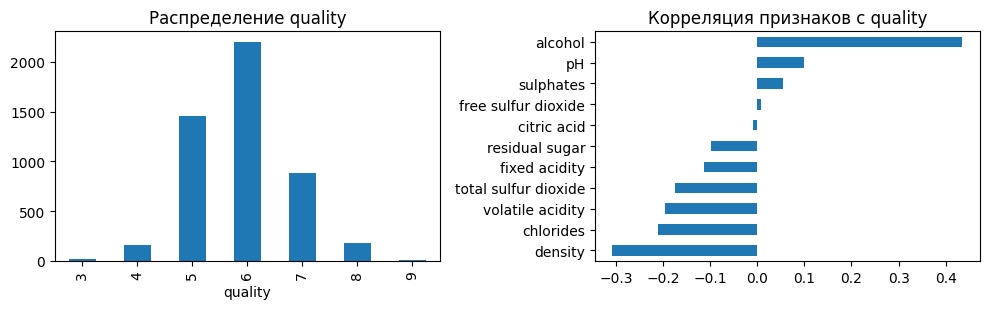

In [2]:
path = find_file("winequality-white.csv")
HAVE_WINE = path is not None
if HAVE_WINE:
    wine = pd.read_csv(path, sep=";")
    print("Размер:", wine.shape); print("\nТипы столбцов:\n", wine.dtypes.value_counts())
    print("\nПропуски:", int(wine.isna().sum().sum()), "| Полных дубликатов строк:", int(wine.duplicated().sum()))
    print("\nОписательная статистика целевого признака:\n", wine["quality"].describe().round(3))
    print("\nРаспределение quality:\n", wine["quality"].value_counts().sort_index())
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    wine["quality"].value_counts().sort_index().plot.bar(ax=ax[0], title="Распределение quality")
    wine.drop(columns="quality").corrwith(wine["quality"]).sort_values().plot.barh(ax=ax[1], title="Корреляция признаков с quality")
    savefig("reg_eda.png")
else:
    print("winequality-white.csv не найден — раздел пропущен")

**Утечка и дубликаты.** Идентификаторов и признаков, раскрывающих `quality`, в наборе нет — все 11 признаков физико-химические.
В белом вине много полных дубликатов строк; при случайном разбиении одна и та же строка могла бы попасть и в train, и в test, что завышает
метрики. Поэтому дубликаты удаляются **до разбиения** (`DROP_DUPLICATES = True`). Пропусков нет; импутация всё равно включена в конвейер.
Целевой признак не масштабируется (шкала 3–9), поэтому MSE/MAE сразу в исходных единицах.

In [3]:
DROP_DUPLICATES = True
if HAVE_WINE:
    df = wine.drop_duplicates().reset_index(drop=True) if DROP_DUPLICATES else wine
    print("После удаления дубликатов:", df.shape)
    X, y = df.drop(columns="quality"), df["quality"].astype("float32")
    Xtr_df, Xva_df, Xte_df, ytr, yva, yte = split_data(X, y, stratify=False)
    Xtr, Xva, Xte, _ = preprocess(Xtr_df, Xva_df, Xte_df)

После удаления дубликатов: (3961, 12)
train=2772  val=594  test=595  (random_state=42, stratify=False)
числовых признаков: 11, категориальных: 0, итоговая размерность: 11


### 1.2 Базовая модель и обучение MLP

In [4]:
def reg_metrics(y, p):
    return dict(MSE=mean_squared_error(y, p), MAE=mean_absolute_error(y, p), R2=r2_score(y, p))

if HAVE_WINE:
    # Базовая модель: прогноз средним по train
    dummy = DummyRegressor(strategy="mean").fit(Xtr, ytr)
    reg_rows, reg_hist, reg_models = [], {}, {}
    reg_rows.append(dict(Модель="DummyRegressor", Описание="mean", Эпох="-",
        **{"Train MSE": reg_metrics(ytr, dummy.predict(Xtr))["MSE"], "Val MSE": reg_metrics(yva, dummy.predict(Xva))["MSE"], "Val R2": reg_metrics(yva, dummy.predict(Xva))["R2"]},
        **{f"Test {k}": v for k, v in reg_metrics(yte, dummy.predict(Xte)).items()}))
    for cfg in CFGS:
        model, h = train_model(cfg, Xtr, ytr, Xva, yva, "regression", max_epochs=200, patience=15)
        reg_hist[cfg["name"]], reg_models[cfg["name"]] = h, model
        P = {k: model.predict(v, verbose=0).ravel() for k, v in dict(tr=Xtr, va=Xva, te=Xte).items()}
        reg_rows.append(dict(Модель=cfg["name"], Описание=describe_cfg(cfg), Эпох=int(np.argmin(h["val_loss"]))+1,
            **{"Train MSE": reg_metrics(ytr, P["tr"])["MSE"], "Val MSE": reg_metrics(yva, P["va"])["MSE"], "Val R2": reg_metrics(yva, P["va"])["R2"]},
            **{f"Test {k}": v for k, v in reg_metrics(yte, P["te"]).items()}))
        print(f"{cfg['name']}: лучшая эпоха {reg_rows[-1]['Эпох']}, val MSE={reg_rows[-1]['Val MSE']:.4f}")
    reg_df = pd.DataFrame(reg_rows)
    reg_df["Переобучение (Val MSE − Train MSE)"] = reg_df["Val MSE"] - reg_df["Train MSE"]
    reg_df.round(4).to_csv("table_C_regression_full.csv", index=False)

MLP-1: лучшая эпоха 89, val MSE=0.5519


MLP-2: лучшая эпоха 42, val MSE=0.5199


MLP-3: лучшая эпоха 23, val MSE=0.5438


MLP-4: лучшая эпоха 41, val MSE=0.5550


MLP-5: лучшая эпоха 5, val MSE=0.5541


### 1.3 Таблица C: результаты (MSE, MAE, R²; шкала `quality`)

        Модель                                                           Описание Эпох  Train MSE  Val MSE  Val R2  Test MSE  Test MAE  Test R2  Переобучение (Val MSE − Train MSE)
DummyRegressor                                                               mean    -     0.7947   0.7933 -0.0072    0.7860    0.6719  -0.0012                             -0.0014
         MLP-1           32, relu, adam (lr=0.001), batch=32, dropout=0.0, L2=0.0   89     0.4485   0.5519  0.2993    0.5620    0.5908   0.2842                              0.1034
         MLP-2        64-32, relu, adam (lr=0.001), batch=32, dropout=0.2, L2=0.0   42     0.4733   0.5199  0.3399    0.5431    0.5763   0.3082                              0.0466
         MLP-3 128-64-32, relu, adam (lr=0.001), batch=32, dropout=0.3, L2=0.0001   23     0.4874   0.5438  0.3096    0.5722    0.5919   0.2712                              0.0564
         MLP-4     64-32, tanh, rmsprop (lr=0.001), batch=32, dropout=0.0, L2=0.0   41     0.4548   

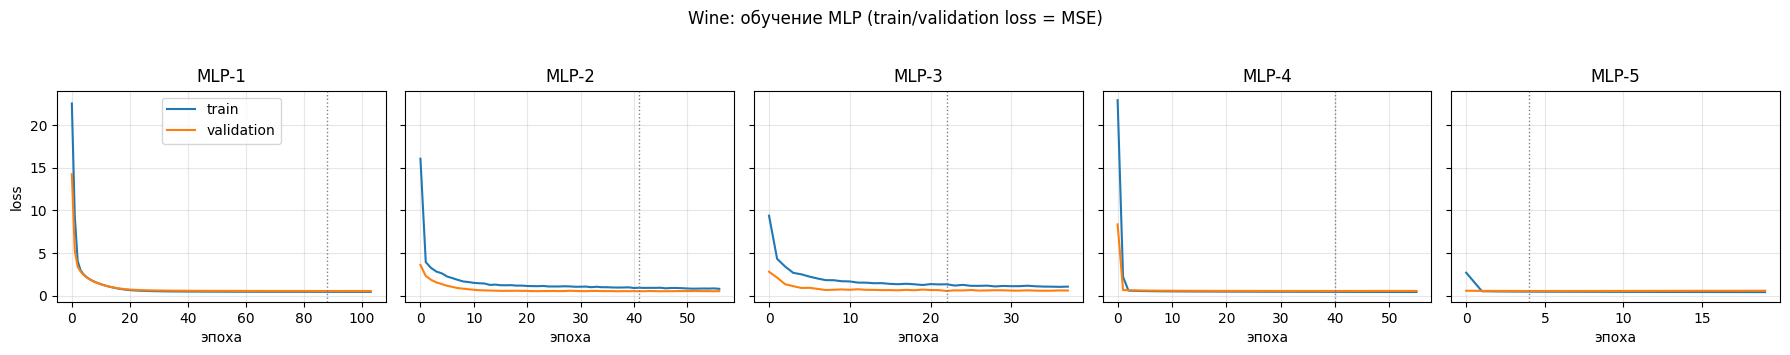

In [5]:
if HAVE_WINE:
    display_cols = ["Модель", "Описание", "Эпох", "Train MSE", "Val MSE", "Val R2", "Test MSE", "Test MAE", "Test R2", "Переобучение (Val MSE − Train MSE)"]
    print(reg_df[display_cols].round(4).to_string(index=False))
    plot_histories(reg_hist, "Wine: обучение MLP (train/validation loss = MSE)", "reg_learning_curves.png")

### 1.4 Выбор лучшей модели (по validation) и итоговая оценка на тесте

Лучшая модель по Val MSE: MLP-2
                   MSE     MAE      R2
MLP (лучшая)    0.5431  0.5763  0.3082
DummyRegressor  0.7860  0.6719 -0.0012


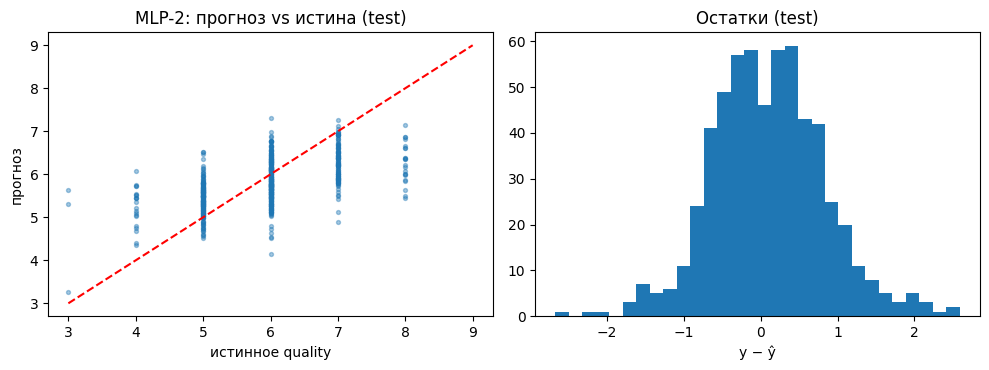

In [6]:
if HAVE_WINE:
    nn = reg_df[reg_df["Модель"].str.startswith("MLP")]
    best_name = nn.loc[nn["Val MSE"].idxmin(), "Модель"]
    print("Лучшая модель по Val MSE:", best_name)
    best = reg_models[best_name]; pte = best.predict(Xte, verbose=0).ravel()
    m = reg_metrics(yte, pte); base = reg_metrics(yte, dummy.predict(Xte))
    print(pd.DataFrame({"MLP (лучшая)": m, "DummyRegressor": base}).T.round(4))
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
    ax[0].scatter(yte, pte + np.random.default_rng(SEED).normal(0, .04, len(pte)), s=8, alpha=.4)
    ax[0].plot([3, 9], [3, 9], "r--"); ax[0].set_xlabel("истинное quality"); ax[0].set_ylabel("прогноз"); ax[0].set_title(f"{best_name}: прогноз vs истина (test)")
    ax[1].hist(yte - pte, bins=30); ax[1].set_title("Остатки (test)"); ax[1].set_xlabel("y − ŷ")
    savefig("reg_best_model.png")

## 2. Бинарная классификация: Diabetes Health Indicators, `Diabetes_012`
Положительный класс (1) = преддиабет или диабет (исходные значения 1 и 2 объединены), отрицательный (0) = нет диабета.
Файл Kaggle: `diabetes_012_health_indicators_BRFSS2015.csv`.

In [7]:
path = find_file("diabetes_012*.csv", "*diabetes*012*.csv")
HAVE_DIAB = path is not None
if HAVE_DIAB:
    d = pd.read_csv(path)
    print("Размер:", d.shape, "| пропусков:", int(d.isna().sum().sum()), "| полных дубликатов:", int(d.duplicated().sum()))
    print("\nИсходное распределение Diabetes_012:\n", d["Diabetes_012"].value_counts().sort_index())
    d["target"] = (d["Diabetes_012"] > 0).astype(int)          # 0 — нет диабета, 1 — преддиабет/диабет
    vc = d["target"].value_counts().sort_index(); print("\nБинарная метка:\n", pd.DataFrame({"n": vc, "доля": (vc/len(d)).round(4)}))
    # Утечки: идентификаторов нет; признаки — анкетные ответы BRFSS, целевой столбец исключаем из X.
    # Дубликаты НЕ удаляем: одинаковые анкеты (бинарные признаки) могут принадлежать разным людям.
    X = d.drop(columns=["Diabetes_012", "target"]); y = d["target"].values
    Xtr_df, Xva_df, Xte_df, ytr_b, yva_b, yte_b = split_data(X, y, stratify=True)
    Xtr_b, Xva_b, Xte_b, _ = preprocess(Xtr_df, Xva_df, Xte_df)
    print("Доля положительного класса train/val/test:", ytr_b.mean().round(4), yva_b.mean().round(4), yte_b.mean().round(4))
    cw = {0: len(ytr_b)/(2*(ytr_b==0).sum()), 1: len(ytr_b)/(2*(ytr_b==1).sum())}   # class_weight только для train
    print("class_weight:", {k: round(v, 3) for k, v in cw.items()})
else:
    print("Файл Diabetes не найден — раздел пропущен (положите diabetes_012_health_indicators_BRFSS2015.csv в DATA_DIR)")

Размер: (253680, 22) | пропусков: 0 | полных дубликатов: 23899

Исходное распределение Diabetes_012:
 Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64

Бинарная метка:
              n    доля
target                
0       213703  0.8424
1        39977  0.1576
train=177575  val=38052  test=38053  (random_state=42, stratify=True)


числовых признаков: 21, категориальных: 0, итоговая размерность: 21
Доля положительного класса train/val/test: 0.1576 0.1576 0.1576
class_weight: {0: np.float64(0.594), 1: np.float64(3.173)}


MLP-1 готово


MLP-2 готово


MLP-3 готово


MLP-4 готово


MLP-5 готово
                Модель                                                            Описание  Порог Эпох  Val ROC_AUC  Recall  Precision  BalancedAcc  ROC_AUC     F1
Базовая (Dummy, prior)                                                                   -   0.50    -       0.5000  0.0000     0.0000       0.5000   0.5000 0.0000
                 MLP-1           32, relu, adam (lr=0.001), batch=512, dropout=0.0, L2=0.0   0.50   26       0.8238  0.7967     0.3299       0.7470   0.8239 0.4666
                 MLP-2        64-32, relu, adam (lr=0.001), batch=512, dropout=0.2, L2=0.0   0.51    8       0.8244  0.7911     0.3333       0.7475   0.8236 0.4690
                 MLP-3 128-64-32, relu, adam (lr=0.001), batch=512, dropout=0.3, L2=0.0001   0.53    5       0.8244  0.7769     0.3401       0.7474   0.8239 0.4731
                 MLP-4     64-32, tanh, rmsprop (lr=0.001), batch=512, dropout=0.0, L2=0.0   0.51   41       0.8205  0.7947     0.3281       0.7452   0.8201 0.4645
   

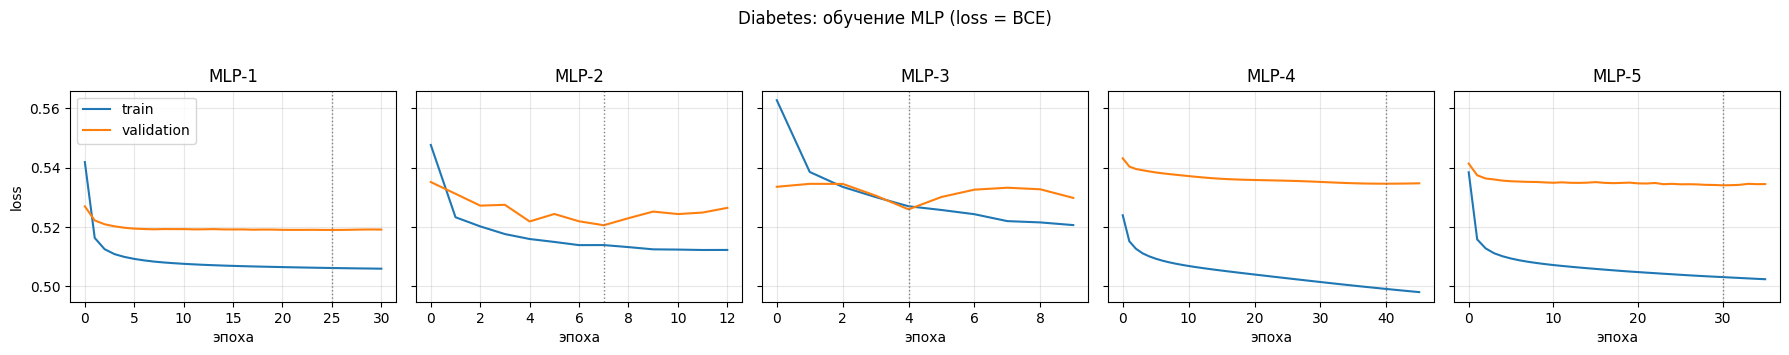

In [8]:
def best_threshold(y, p):
    ths = np.arange(0.05, 0.951, 0.01)
    return float(ths[int(np.argmax([balanced_accuracy_score(y, (p >= t).astype(int)) for t in ths]))])

def bin_metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    return dict(Recall=recall_score(y, pred), Precision=precision_score(y, pred, zero_division=0),
                BalancedAcc=balanced_accuracy_score(y, pred), ROC_AUC=roc_auc_score(y, p), F1=f1_score(y, pred))

if HAVE_DIAB:
    dm = DummyClassifier(strategy="prior").fit(Xtr_b, ytr_b)
    pte = dm.predict_proba(Xte_b)[:, 1]
    bin_rows = [dict(Модель="Базовая (Dummy, prior)", Описание="-", Порог=0.5, Эпох="-", **{"Val ROC_AUC": 0.5}, **bin_metrics(yte_b, pte, 0.5))]
    bin_hist, bin_models, bin_probs = {}, {}, {}
    for cfg0 in CFGS:
        cfg = {**cfg0, "batch": 512}      # 177 тыс. объектов: крупный batch ускоряет обучение
        model, h = train_model(cfg, Xtr_b, ytr_b, Xva_b, yva_b, "binary", class_weight=cw, max_epochs=60, patience=5)
        pva = model.predict(Xva_b, verbose=0).ravel(); pte = model.predict(Xte_b, verbose=0).ravel()
        thr = best_threshold(yva_b, pva)                    # порог выбирается на validation
        bin_hist[cfg["name"]], bin_models[cfg["name"]], bin_probs[cfg["name"]] = h, model, (pva, pte, thr)
        bin_rows.append(dict(Модель=cfg["name"], Описание=describe_cfg(cfg), Порог=round(thr, 2), Эпох=int(np.argmin(h["val_loss"]))+1,
                             **{"Val ROC_AUC": roc_auc_score(yva_b, pva)}, **bin_metrics(yte_b, pte, thr)))
        print(cfg["name"], "готово")
    bin_df = pd.DataFrame(bin_rows); bin_df.round(4).to_csv("table_A_binary.csv", index=False)
    print(bin_df.round(4).to_string(index=False))
    plot_histories(bin_hist, "Diabetes: обучение MLP (loss = BCE)", "bin_learning_curves.png")

Лучшая модель по Val ROC-AUC: MLP-2, порог = 0.51


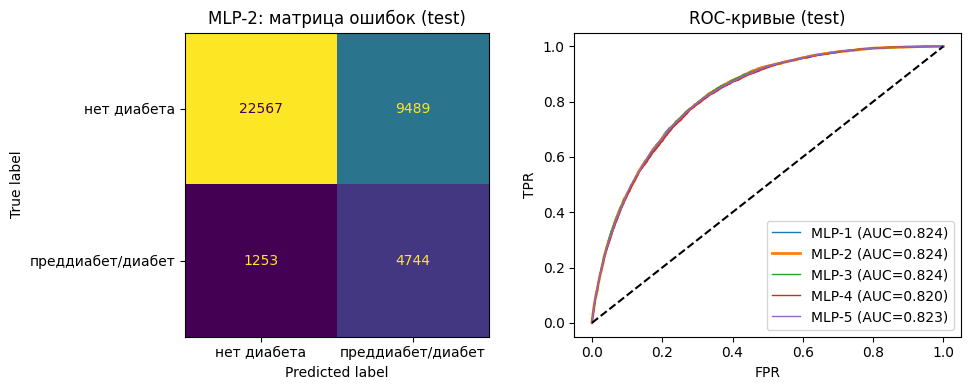

In [9]:
if HAVE_DIAB:
    nn = bin_df[bin_df["Модель"].str.startswith("MLP")]
    bname = nn.loc[nn["Val ROC_AUC"].idxmax(), "Модель"]; pva, pte, thr = bin_probs[bname]
    print(f"Лучшая модель по Val ROC-AUC: {bname}, порог = {thr:.2f}")
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ConfusionMatrixDisplay(confusion_matrix(yte_b, (pte >= thr).astype(int)), display_labels=["нет диабета", "преддиабет/диабет"]).plot(ax=ax[0], colorbar=False)
    ax[0].set_title(f"{bname}: матрица ошибок (test)")
    for n_, (_, pt_, _) in bin_probs.items():
        f, t, _ = roc_curve(yte_b, pt_); ax[1].plot(f, t, label=f"{n_} (AUC={roc_auc_score(yte_b, pt_):.3f})", lw=2 if n_ == bname else 1)
    ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend(); ax[1].set_title("ROC-кривые (test)")
    savefig("bin_best.png")

## 3. Многоклассовая классификация: Body Performance, `class`
Файл Kaggle: `bodyPerformance.csv`. Классы A, B, C, D кодируются числами; признак `gender` — категориальный (One-Hot).

In [10]:
path = find_file("bodyPerformance*.csv", "*body*performance*.csv")
HAVE_BODY = path is not None
if HAVE_BODY:
    b = pd.read_csv(path)
    print("Размер:", b.shape, "| пропусков:", int(b.isna().sum().sum()), "| полных дубликатов:", int(b.duplicated().sum()))
    print(b.dtypes.to_string())
    vc = b["class"].value_counts().sort_index(); print("\nКлассы:\n", pd.DataFrame({"n": vc, "доля": (vc/len(b)).round(4)}))
    le = LabelEncoder(); y_m = le.fit_transform(b["class"]); CLASSES = list(le.classes_); K = len(CLASSES)
    X = b.drop(columns=["class"])      # идентификаторов и признаков с утечкой нет
    Xtr_df, Xva_df, Xte_df, ytr_m, yva_m, yte_m = split_data(X, y_m, stratify=True)
    Xtr_m, Xva_m, Xte_m, _ = preprocess(Xtr_df, Xva_df, Xte_df)
else:
    print("Файл Body Performance не найден — раздел пропущен (положите bodyPerformance.csv в DATA_DIR)")

Размер: (13393, 12) | пропусков: 0 | полных дубликатов: 1
age                        float64
gender                         str
height_cm                  float64
weight_kg                  float64
body fat_%                 float64
diastolic                  float64
systolic                   float64
gripForce                  float64
sit and bend forward_cm    float64
sit-ups counts             float64
broad jump_cm              float64
class                          str

Классы:
           n    доля
class              
A      3348  0.2500
B      3347  0.2499
C      3349  0.2501
D      3349  0.2501
train=9375  val=2009  test=2009  (random_state=42, stratify=True)
числовых признаков: 10, категориальных: 1, итоговая размерность: 12


MLP-1 готово


MLP-2 готово


MLP-3 готово


MLP-4 готово


MLP-5 готово
         Модель  Val BalAcc  Test Accuracy  Test BalAcc  Test macro ROC-AUC (OvR)  Test macro F1
Базовая (Dummy)      0.2500         0.2499       0.2500                    0.5000         0.1000
          MLP-1      0.7292         0.7451       0.7452                    0.9213         0.7445
          MLP-2      0.7481         0.7521       0.7522                    0.9278         0.7518
          MLP-3      0.7556         0.7636       0.7636                    0.9306         0.7647
          MLP-4      0.7362         0.7556       0.7556                    0.9244         0.7556
          MLP-5      0.7357         0.7526       0.7527                    0.9246         0.7527

         Модель       Метрика      A      B      C      D  Macro avg  Weighted avg
Базовая (Dummy)     precision 0.2499 0.0000 0.0000 0.0000     0.0625        0.0624
Базовая (Dummy)        recall 1.0000 0.0000 0.0000 0.0000     0.2500        0.2499
Базовая (Dummy)      f1-score 0.3998 0.0000 0.0000 0.0000 

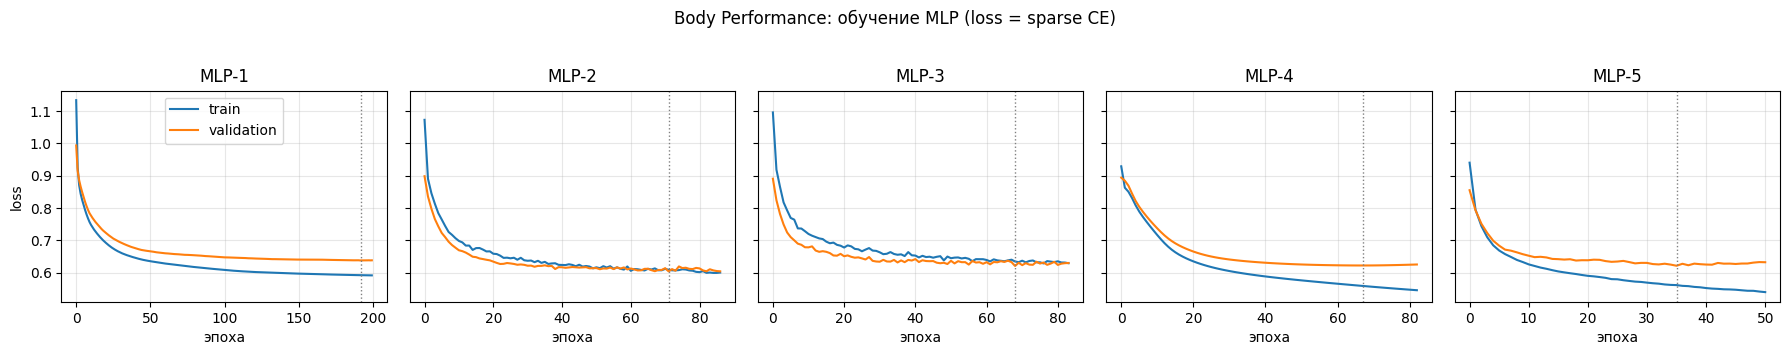

In [11]:
def multi_eval(y, proba, k):
    pred = proba.argmax(1)
    rep = classification_report(y, pred, target_names=CLASSES, output_dict=True, zero_division=0)
    Y = label_binarize(y, classes=list(range(k)))
    aucs = [roc_auc_score(Y[:, i], proba[:, i]) for i in range(k)]          # One-vs-Rest
    return dict(rep=rep, bal=balanced_accuracy_score(y, pred), aucs=aucs, macro_auc=float(np.mean(aucs)), acc=accuracy_score(y, pred), pred=pred)

if HAVE_BODY:
    dm = DummyClassifier(strategy="prior").fit(Xtr_m, ytr_m)
    mc = {"Базовая (Dummy)": multi_eval(yte_m, dm.predict_proba(Xte_m), K)}
    mc_val, mc_hist, mc_models, mc_proba = {"Базовая (Dummy)": multi_eval(yva_m, dm.predict_proba(Xva_m), K)}, {}, {}, {}
    for cfg in CFGS:
        model, h = train_model(cfg, Xtr_m, ytr_m, Xva_m, yva_m, "multiclass", n_classes=K, max_epochs=200, patience=15)
        mc_hist[cfg["name"]], mc_models[cfg["name"]] = h, model
        mc_proba[cfg["name"]] = model.predict(Xte_m, verbose=0)
        mc[cfg["name"]] = multi_eval(yte_m, mc_proba[cfg["name"]], K)
        mc_val[cfg["name"]] = multi_eval(yva_m, model.predict(Xva_m, verbose=0), K)
        print(cfg["name"], "готово")
    # Сводная таблица
    summ = pd.DataFrame([dict(Модель=n, **{"Val BalAcc": mc_val[n]["bal"]}, **{"Test Accuracy": r["acc"], "Test BalAcc": r["bal"], "Test macro ROC-AUC (OvR)": r["macro_auc"],
                              "Test macro F1": r["rep"]["macro avg"]["f1-score"]}) for n, r in mc.items()])
    print(summ.round(4).to_string(index=False)); summ.round(4).to_csv("table_B_summary.csv", index=False)
    # Таблица B: метрики по классам
    rows = []
    for n, r in mc.items():
        for met in ["precision", "recall", "f1-score"]:
            rows.append({"Модель": n, "Метрика": met, **{c: r["rep"][c][met] for c in CLASSES}, "Macro avg": r["rep"]["macro avg"][met], "Weighted avg": r["rep"]["weighted avg"][met]})
        rows.append({"Модель": n, "Метрика": "ROC-AUC (OvR)", **{c: a for c, a in zip(CLASSES, r["aucs"])}, "Macro avg": r["macro_auc"], "Weighted avg": np.nan})
    tabB = pd.DataFrame(rows); tabB.round(4).to_csv("table_B_per_class.csv", index=False); print(); print(tabB.round(4).to_string(index=False))
    plot_histories(mc_hist, "Body Performance: обучение MLP (loss = sparse CE)", "multi_learning_curves.png")

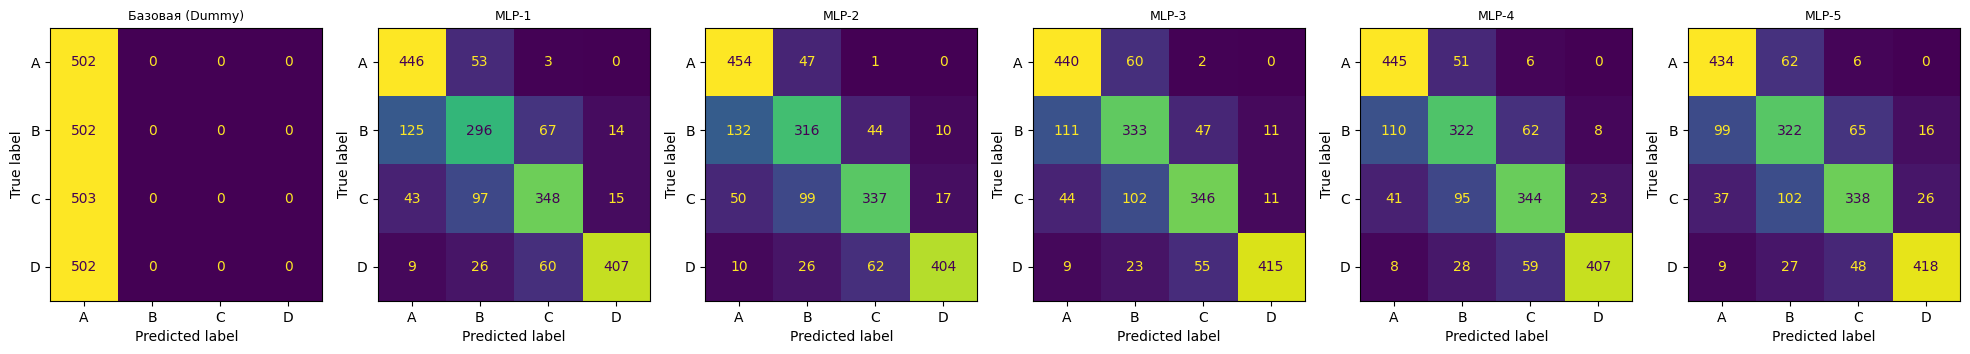

Лучшая модель по Val Balanced Accuracy: MLP-3


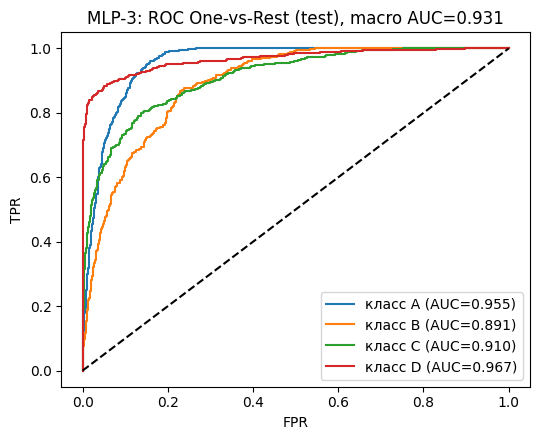

In [12]:
if HAVE_BODY:
    # Матрицы ошибок всех моделей
    names = list(mc.keys()); fig, axs = plt.subplots(1, len(names), figsize=(3.3*len(names), 3.3))
    for ax, n in zip(axs, names):
        ConfusionMatrixDisplay(confusion_matrix(yte_m, mc[n]["pred"]), display_labels=CLASSES).plot(ax=ax, colorbar=False); ax.set_title(n, fontsize=9)
    savefig("multi_confusion_all.png")
    # Лучшая модель по Val Balanced Accuracy и её ROC-кривые OvR
    nn_names = [n for n in mc if n.startswith("MLP")]; mname = max(nn_names, key=lambda n: mc_val[n]["bal"])
    print("Лучшая модель по Val Balanced Accuracy:", mname)
    Y = label_binarize(yte_m, classes=list(range(K))); plt.figure(figsize=(5.5, 4.5))
    for i, c in enumerate(CLASSES):
        f, t, _ = roc_curve(Y[:, i], mc_proba[mname][:, i]); plt.plot(f, t, label=f"класс {c} (AUC={mc[mname]['aucs'][i]:.3f})")
    plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(); plt.title(f"{mname}: ROC One-vs-Rest (test), macro AUC={mc[mname]['macro_auc']:.3f}")
    savefig("multi_roc_best.png")

## 4. Выводы

### Регрессия (Wine Quality, white) — результаты выполненного эксперимента
* После удаления 937 дубликатов осталось 3961 объектов; разбиение 70/15/15 → 2772 / 594 / 595 (seed=42).
* Базовая модель (`DummyRegressor`, среднее): Test MSE = 0.786, MAE = 0.672, R² ≈ 0.
* Лучшая по validation — **MLP-2** (64-32, ReLU, Adam, Dropout 0.2): Test MSE = 0.543, MAE = 0.576, **R² = 0.308**.
  Ошибка в среднем около 0.58 балла по шкале качества; MSE снижен примерно на 31 % относительно базовой модели.
* Ориентир R² ≥ 0.80 **не достигнут**. Причины: целевой признак — медиана субъективных оценок экспертов (целые 3–9, сильно сконцентрированы
  вокруг 5–6), 11 физико-химических признаков объясняют только часть дисперсии; в данных есть шум оценок и несбалансированные крайние значения.
  Все пять архитектур дают R² 0.25–0.31, то есть рост глубины/ширины не помогает: MLP-3 (самая глубокая) не лучше MLP-2,
  а MLP-1 (компактная) переобучается сильнее (разрыв Val−Train MSE ≈ 0.10 против 0.05 у MLP-2). Dropout/L2 и Early Stopping уменьшают разрыв.
* Возможные улучшения: постановка как порядковой классификации, градиентный бустинг/Random Forest как сильный бейзлайн, подбор признаков,
  объединение red+white с признаком типа вина.

### Бинарная и многоклассовая задачи
Выводы по Diabetes и Body Performance формулируются после запуска разделов 2 и 3 на соответствующих файлах Kaggle.